## Modeling Pipeline

Trains Logistic Regression and Random Forest, saves pipelines to `results/`,
and writes evaluation figures to `figures/`.

**Critical:** this notebook **asserts** that `tenure_group` is absent from the
fitted pipeline. If it's present, the config change didn't propagate — cell
8 will raise.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")

import pandas as pd
from sklearn.model_selection import train_test_split

import src.config as cfg
from src.load_data import load_raw_data
from src.preprocess import clean_data, split_features_target
from src.train import (
    build_logistic_pipeline, build_random_forest_pipeline, train_model,
)
from src.evaluate import (
    evaluate_classifier, print_classification_report,
    plot_roc_pr_curves, plot_threshold_analysis, find_best_f1_threshold,
)

print("DERIVED_CATEGORICAL_FEATURES:", cfg.DERIVED_CATEGORICAL_FEATURES)
assert cfg.DERIVED_CATEGORICAL_FEATURES == [], (
    f"Config not updated! DERIVED_CATEGORICAL_FEATURES = {cfg.DERIVED_CATEGORICAL_FEATURES}"
)

DERIVED_CATEGORICAL_FEATURES: []


In [2]:
clean = clean_data(load_raw_data())
X, y = split_features_target(clean)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.TEST_SIZE, stratify=y, random_state=cfg.RANDOM_STATE,
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train churn: {y_train.mean():.4f}  |  Test churn: {y_test.mean():.4f}")
print(f"X columns ({len(X.columns)}): {X.columns.tolist()}")

Train: (5634, 21)  |  Test: (1409, 21)
Train churn: 0.2654  |  Test churn: 0.2654
X columns (21): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'AvgMonthlyCharge']


In [3]:
lr, t_lr = train_model(build_logistic_pipeline(), X_train, y_train)
print(f"LR trained in {t_lr:.2f}s\n")

print("=== Logistic Regression — TEST SET ===")
print_classification_report(lr, X_test, y_test)

lr_test = evaluate_classifier(lr, X_test, y_test)
print("Metrics:", lr_test)

LR trained in 0.03s

=== Logistic Regression — TEST SET ===
              precision    recall  f1-score   support

    No churn     0.9033    0.7217    0.8024      1035
       Churn     0.5052    0.7861    0.6151       374

    accuracy                         0.7388      1409
   macro avg     0.7042    0.7539    0.7087      1409
weighted avg     0.7976    0.7388    0.7526      1409

Confusion matrix (rows=true, cols=pred):
        No    Yes
No     747    288
Yes     80    294
Metrics: {'threshold': 0.5, 'accuracy': 0.7388, 'precision': 0.5052, 'recall': 0.7861, 'f1': 0.6151, 'roc_auc': 0.8418, 'pr_auc': 0.633}


In [4]:
rf, t_rf = train_model(build_random_forest_pipeline(), X_train, y_train)
print(f"RF trained in {t_rf:.2f}s\n")

print("=== Random Forest — TEST SET ===")
print_classification_report(rf, X_test, y_test)

rf_test = evaluate_classifier(rf, X_test, y_test)
print("Metrics:", rf_test)

RF trained in 1.27s

=== Random Forest — TEST SET ===
              precision    recall  f1-score   support

    No churn     0.8551    0.8097    0.8318      1035
       Churn     0.5408    0.6203    0.5778       374

    accuracy                         0.7594      1409
   macro avg     0.6979    0.7150    0.7048      1409
weighted avg     0.7717    0.7594    0.7644      1409

Confusion matrix (rows=true, cols=pred):
        No    Yes
No     838    197
Yes    142    232
Metrics: {'threshold': 0.5, 'accuracy': 0.7594, 'precision': 0.5406, 'recall': 0.623, 'f1': 0.5789, 'roc_auc': 0.821, 'pr_auc': 0.6135}


In [5]:
comparison = pd.DataFrame({
    "LogisticRegression": lr_test,
    "RandomForest": rf_test,
}).T
print(comparison)

                    threshold  accuracy  precision  recall      f1  roc_auc  \
LogisticRegression        0.5    0.7388     0.5052  0.7861  0.6151   0.8418   
RandomForest              0.5    0.7594     0.5406  0.6230  0.5789   0.8210   

                    pr_auc  
LogisticRegression  0.6330  
RandomForest        0.6135  


In [6]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
naive = pd.Series(0, index=y_test.index)
print(f"Always-'No' baseline:  accuracy={accuracy_score(y_test, naive):.4f}"
      f"  recall={recall_score(y_test, naive):.4f}"
      f"  f1={f1_score(y_test, naive):.4f}")
print("↑ 73% accuracy with zero churners caught — the accuracy trap.")

Always-'No' baseline:  accuracy=0.7346  recall=0.0000  f1=0.0000
↑ 73% accuracy with zero churners caught — the accuracy trap.


In [7]:
# ============================================================
# HARD GUARD — this cell must PASS before saving.
# If tenure_group appears here, the config change didn't
# propagate and the .joblib will be poisoned.
# ============================================================
names = lr.named_steps["preprocessor"].get_feature_names_out()
bad = [n for n in names if "tenure_group" in n]
assert not bad, (
    f"FAIL: {len(bad)} tenure_group features in fitted model: {bad}. "
    f"Check _engineer_features() and build_preprocessor()."
)
print(f"OK: {len(names)} features, no tenure_group.")

OK: 42 features, no tenure_group.


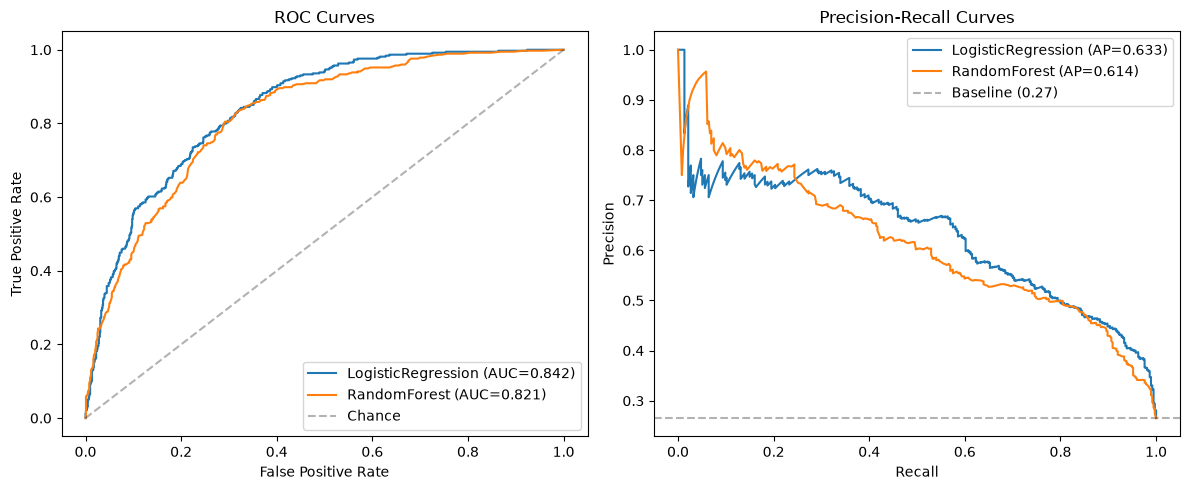

Saved → /home/kakarotbot/telco-churn-prediction/figures/roc_pr_curves.png

=== LogisticRegression ===


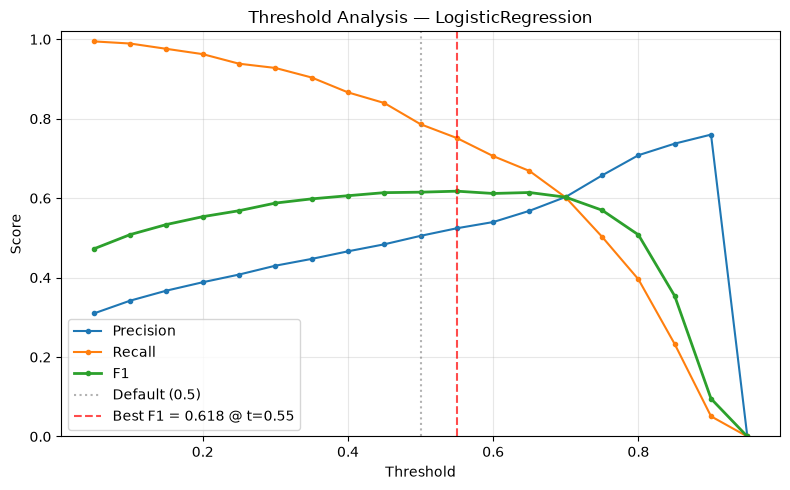

Saved → /home/kakarotbot/telco-churn-prediction/figures/threshold_logisticregression.png
Best F1 = 0.6176 at threshold=0.55 (precision=0.5243, recall=0.7513)

=== RandomForest ===


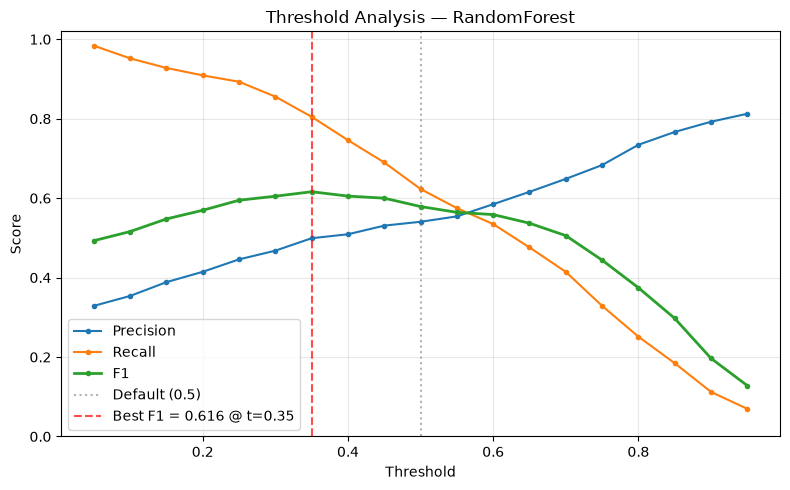

Saved → /home/kakarotbot/telco-churn-prediction/figures/threshold_randomforest.png
Best F1 = 0.6162 at threshold=0.35 (precision=0.4992, recall=0.8048)


In [8]:
plot_roc_pr_curves(
    {"LogisticRegression": lr, "RandomForest": rf},
    X_test, y_test,
)
for name, model in [("LogisticRegression", lr), ("RandomForest", rf)]:
    print(f"\n=== {name} ===")
    plot_threshold_analysis(model, X_test, y_test, name=name)

In [9]:
import joblib

cfg.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(lr, cfg.RESULTS_DIR / "logistic_regression.joblib")
joblib.dump(rf, cfg.RESULTS_DIR / "random_forest.joblib")

comparison.to_csv(cfg.RESULTS_DIR / "model_comparison.csv")

lr_best_t, lr_best_row = find_best_f1_threshold(lr, X_test, y_test)
rf_best_t, rf_best_row = find_best_f1_threshold(rf, X_test, y_test)
pd.DataFrame([
    {"model": "LogisticRegression", "default_threshold": 0.5,
     "best_f1_threshold": lr_best_t, **lr_best_row},
    {"model": "RandomForest", "default_threshold": 0.5,
     "best_f1_threshold": rf_best_t, **rf_best_row},
]).to_csv(cfg.RESULTS_DIR / "threshold_analysis.csv", index=False)

print("Saved:")
for f in sorted(cfg.RESULTS_DIR.glob("*")):
    print(f"  {f.name}")

Saved:
  logistic_regression.joblib
  model_comparison.csv
  random_forest.joblib
  threshold_analysis.csv


In [10]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from src.train import build_preprocessor

smote_pipeline = ImbPipeline([
    ("preprocessor", build_preprocessor()),
    ("smote", SMOTE(random_state=cfg.RANDOM_STATE)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=cfg.RANDOM_STATE)),
])
smote_pipeline.fit(X_train, y_train)
smote_metrics = evaluate_classifier(smote_pipeline, X_test, y_test)

print("SMOTE + LR:      ", smote_metrics)
print("Class weight LR: ", lr_test)
print("\nDelta (SMOTE - class_weight):")
print(pd.Series(smote_metrics) - pd.Series(lr_test))

SMOTE + LR:       {'threshold': 0.5, 'accuracy': 0.7346, 'precision': 0.5, 'recall': 0.7968, 'f1': 0.6144, 'roc_auc': 0.8394, 'pr_auc': 0.6257}
Class weight LR:  {'threshold': 0.5, 'accuracy': 0.7388, 'precision': 0.5052, 'recall': 0.7861, 'f1': 0.6151, 'roc_auc': 0.8418, 'pr_auc': 0.633}

Delta (SMOTE - class_weight):
threshold    0.0000
accuracy    -0.0042
precision   -0.0052
recall       0.0107
f1          -0.0007
roc_auc     -0.0024
pr_auc      -0.0073
dtype: float64
